In [8]:
import numpy as np
import pandas as pd
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patches as mpatches



In [9]:
nest_depth = 0.6                                                                                   # m
well_offsets = {"A1": -1.657, "B1": 0.888, "B2": 1.602, "B3": 0.043}                  # cmH2O, "A2": 1.602
baro_offset = -0.829                                                                               # cmH2O

well_z = {"A1": 3.945, "B1": 2.820, "B2": 2.752, "B3": 2.252}                         # m, "A2": 4.076 REMOVED
well_b = {"A1": 0, "B1": 0.400, "B2": 0.442, "B3": 0.334}                                 # m, "A2": 0 REMOVED
well_toc = {k: well_z[k] + well_b[k] for k in well_z}                                              # m
CL = 2.044 - 0.097 - 0.100                                                                         # m

well_x = {'B1': 36.5, 'B2': 46, 'B3': 55}
wellA_x = {'A1': 23.5}

colours = ["#0a91a1", "#74c9b9", "#f47c53", "#f8a953"]

In [10]:
folder = Path("../data/groundwater/DiverCSV")

def read_diver(file):
    df = pd.read_csv(file, skiprows=51, sep=",", encoding="cp1252", usecols=[0, 1])[:-1]
    df["Date/time"] = pd.to_datetime(df["Date/time"])
    df["Pressure[cmH2O]"] = pd.to_numeric(df["Pressure[cmH2O]"], errors="coerce")
    return df.dropna().sort_values("Date/time")

files = [f for f in folder.glob("*.CSV") if f.stem.split("_")[0] in well_offsets]
all_divers = pd.concat([read_diver(f).assign(Diver=f.stem.split("_")[0]) for f in files], ignore_index=True)
all_divers['Pressure[mH2O]'] = (all_divers['Pressure[cmH2O]'] - all_divers['Diver'].map(well_offsets)) / 100

baro = read_diver(next(folder.glob("Baro*.CSV")))
baro['Pressure[mH2O]'] = (baro['Pressure[cmH2O]'] - baro_offset) / 100

tranB = pd.read_csv('../data/groundwater/well_transect_profile.csv')
tranB['z'] = tranB[['Monday', 'Tuesday', 'Wednesday']].mean(axis=1)

tranA = pd.read_csv('../data/groundwater/wellA_transect_profile.csv')
tranA['z'] = tranA[['Monday', 'Tuesday', 'Wednesday']].mean(axis=1)

raw_tides = pd.read_csv('../data/water_levels/QUINTA_tides_2030.csv')


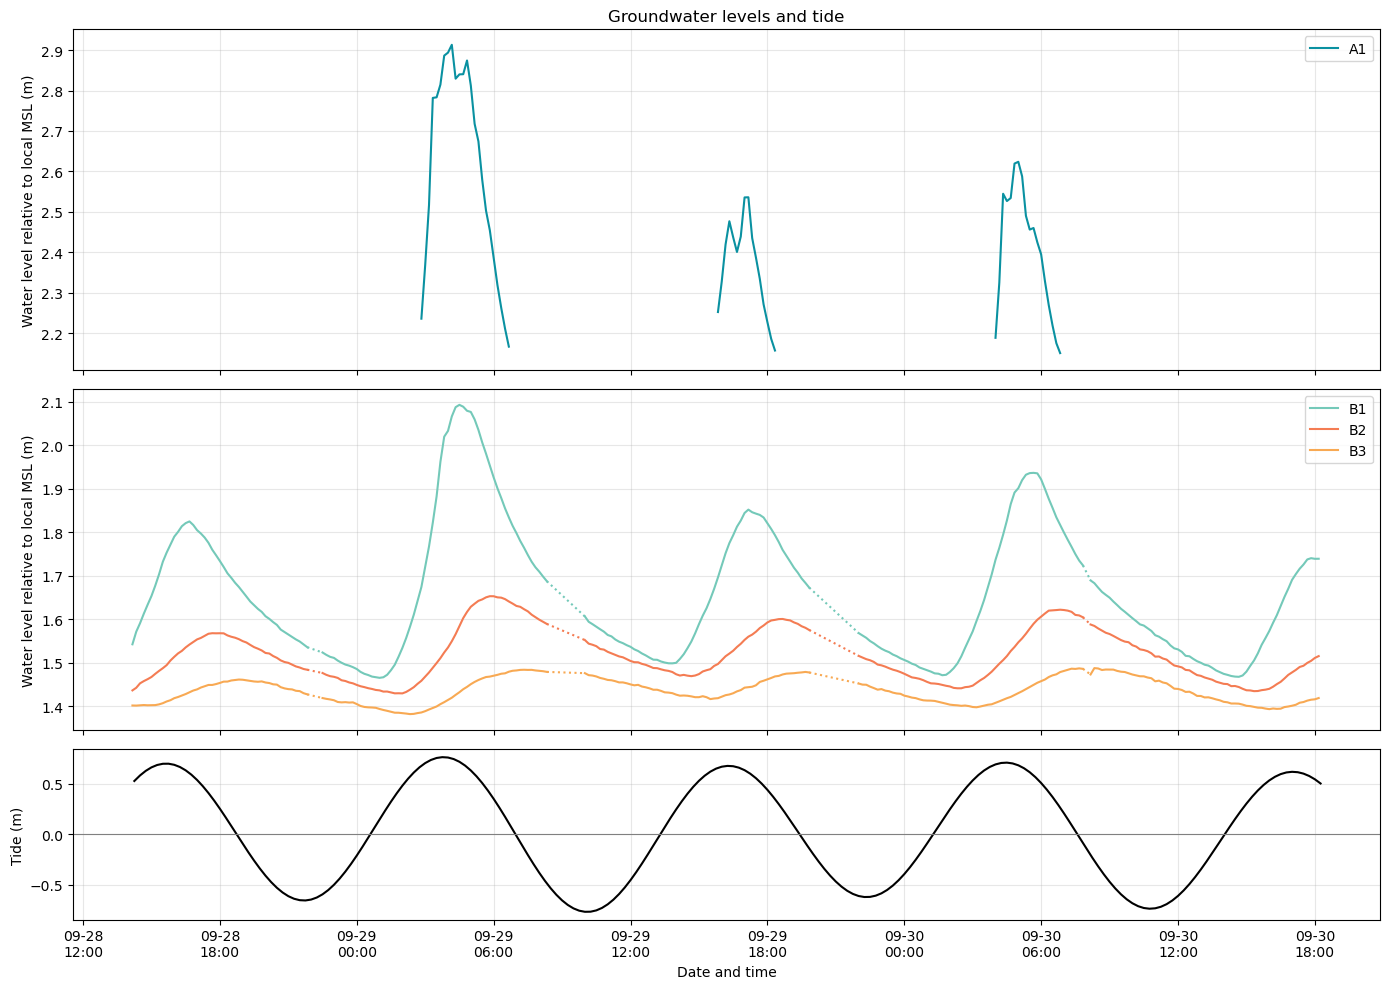

In [ ]:
start = '2026-09-28 14:15:00'
end = '2026-09-30 18:15:00'

baro_at_diver_time = np.interp(all_divers['Date/time'].astype('int64'), baro['Date/time'].astype('int64'), baro['Pressure[mH2O]'])

all_divers['WC'] = all_divers['Pressure[mH2O]'] - baro_at_diver_time
all_divers['WL'] = all_divers['Diver'].map(well_toc) - CL + all_divers['WC']
all_divers.loc[all_divers['WC'] < 0.05, 'WL'] = np.nan
wl = all_divers.loc[all_divers['Date/time'].between(start, end) & (all_divers['WC'] > 0.05)].copy()

tides = raw_tides.copy()
tides['dates'] = pd.to_datetime(tides['dates'], utc=True).dt.tz_localize(None) + pd.Timedelta(hours=-6)
tides = tides.loc[tides['dates'].between(start, end)].copy()

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 10), sharex=True, gridspec_kw={"height_ratios": [3, 3, 1.5]})

well_colours = {name: colours[i % len(colours)] for i, name in enumerate(sorted(wl['Diver'].dropna().unique()))}
well_axes = {'A': ax1, 'B': ax2}

max_interp_gap = pd.Timedelta(hours=6)
max_interp_points = int(max_interp_gap / pd.Timedelta(minutes=5))

for name, df in wl.groupby("Diver"):
    s = df.set_index('Date/time')['WL'].resample('10min').mean()
    med = s.rolling(7, center=True, min_periods=3).median()
    s[(s - med).abs() > 0.5] = np.nan
    ax = well_axes.get(name[0])
    color = well_colours[name]
    ax.plot(s.index.to_numpy(), s.to_numpy(), label=name, color=color, linewidth=1.5)
    
    if name[0] != 'A':
        interpolated = s.interpolate(method='time', limit=max_interp_points, limit_area='inside')
        gap = s.isna() & interpolated.notna()
        bridge = interpolated.where(gap | gap.shift(1, fill_value=False) | gap.shift(-1, fill_value=False))
        ax.plot(bridge.index.to_numpy(), bridge.to_numpy(), color=color, linestyle=':', linewidth=1.5)

ax1.set_ylabel('Water level relative to local MSL (m)')
ax1.set_title('Groundwater levels and tide')
ax1.legend()
ax1.grid(alpha=0.3)

ax2.set_ylabel('Water level relative to local MSL (m)')
ax2.legend()
ax2.grid(alpha=0.3)

ax3.plot(tides["dates"].to_numpy(), tides["tide"].to_numpy(), color='k', linewidth=1.5)
ax3.axhline(0, color='gray', lw=0.8)
ax3.set_ylabel("Tide (m)")
ax3.set_xlabel("Date and time")
ax3.grid(alpha=0.3)

ax3.xaxis.set_major_locator(mdates.AutoDateLocator())
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d\n%H:%M"))
fig.tight_layout()


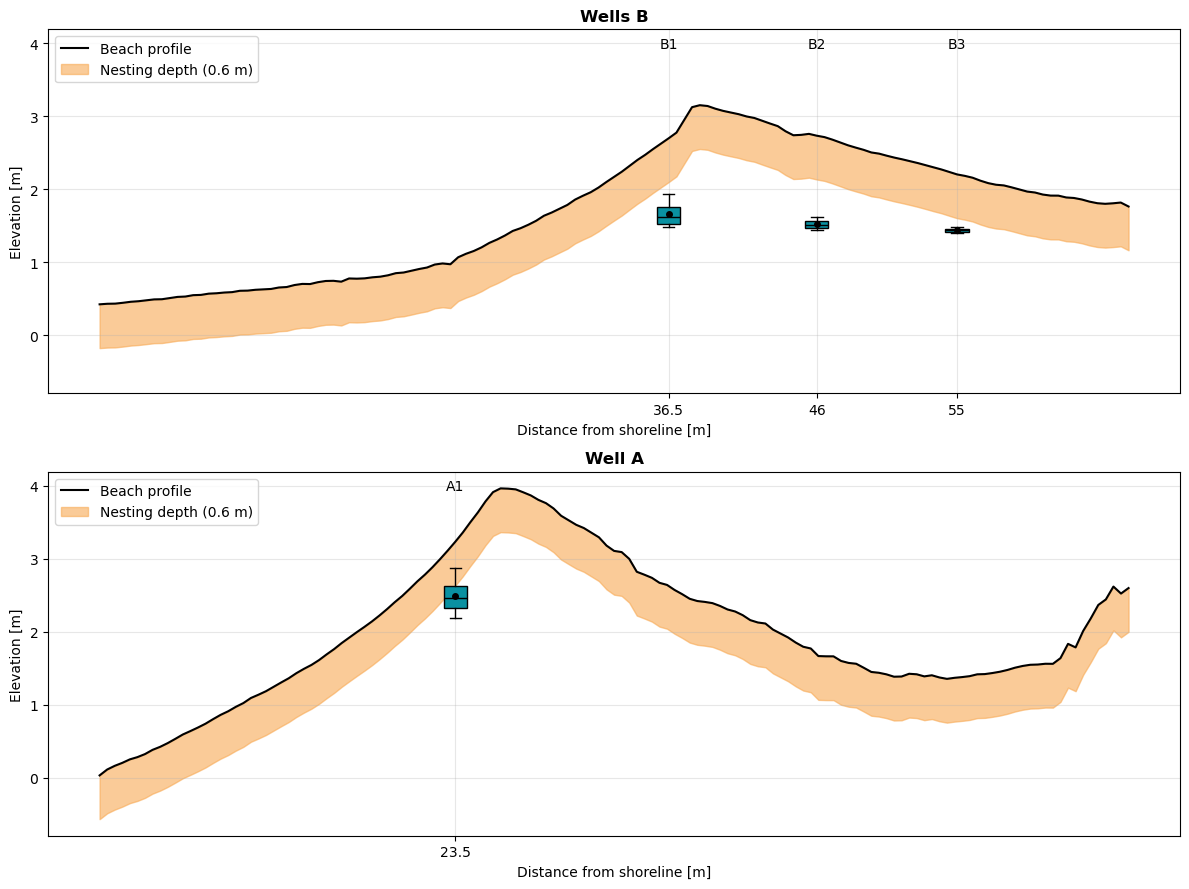

In [12]:
box_style = dict(whis=(5, 95), showfliers=False, showmeans=True, patch_artist=True,
                 boxprops=dict(facecolor='#0a91a1'), medianprops=dict(color='k'),
                 meanprops=dict(marker='o', markerfacecolor='k', markeredgecolor='k', markersize=4))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9), sharey=True)

ax1.plot(tranB['distance_m'], tranB['z'], color='k', label='Beach profile')
ax1.fill_between(tranB['distance_m'], tranB['z'] - nest_depth, tranB['z'], color='#f8a953', alpha=0.6,
                 label=f'Nesting depth (0.6 m)')

for w, x in well_x.items():
    ax1.boxplot(wl.loc[wl['Diver'] == w, 'WL'].dropna(), positions=[x], widths=1.5, **box_style)
    ax1.text(x, 0.98, w, ha="center", va="top", transform=ax1.get_xaxis_transform())

ax1.set_title('Wells B', fontweight='bold')
ax1.set_xlabel('Distance from shoreline [m]')
ax1.set_ylabel('Elevation [m]')
ax1.legend(loc='upper left')
ax1.grid(alpha=0.3)

ax2.plot(tranA['distance_m'], tranA['z'], color='k', label='Beach profile')
ax2.fill_between(tranA['distance_m'], tranA['z'] - nest_depth, tranA['z'], color='#f8a953', alpha=0.6,
                 label=f'Nesting depth (0.6 m)')

for w, x in wellA_x.items():
    ax2.boxplot(wl.loc[wl['Diver'] == w, 'WL'].dropna(), positions=[x], widths=1.5, **box_style)
    ax2.text(x, 0.98, w, ha="center", va="top", transform=ax2.get_xaxis_transform())

ax2.set_title("Well A", fontweight="bold")
ax2.set_xlabel("Distance from shoreline [m]")
ax2.set_ylabel("Elevation [m]")
ax2.legend(loc='upper left')
ax2.grid(alpha=0.3)


plt.tight_layout()